2026-11-10 03:05:41,129 | INFO     | src.db_sql | Tabla 'datos_limpios' leída: 174116 filas, 20 columnas
2026-11-10 03:05:45,181 | INFO     | src.visualization | Figura guardada: precio_m2_por_anio.png
2026-11-10 03:05:46,252 | INFO     | src.db_mongo | Mongo 'metricas' [aleatorio]: 3 documentos leídos (run_id=20261110_022250)
2026-11-10 03:05:46,995 | INFO     | src.db_mongo | Mongo 'metricas' [temporal]: 3 documentos leídos (run_id=20261110_022250)


,escenario,model,accuracy,precision_macro,recall_macro,f1_macro
0,aleatorio,logreg,0.6189,0.6131,0.6189,0.6151
1,aleatorio,random_forest,0.6784,0.6777,0.6784,0.6780
2,aleatorio,dummy,0.3325,0.3325,0.3325,0.3325
3,temporal,logreg,0.6078,0.6016,0.6078,0.6037
4,temporal,random_forest,0.6411,0.6414,0.6411,0.6413
5,temporal,dummy,0.3334,0.3334,0.3334,0.3334


2026-11-10 03:05:51,539 | INFO     | src.visualization | Figura guardada: comparacion_modelos.png
2026-11-10 03:05:53,526 | INFO     | src.visualization | Figura guardada: matrices_confusion_aleatorio.png
2026-11-10 03:05:55,417 | INFO     | src.visualization | Figura guardada: matrices_confusion_temporal.png
2026-11-10 03:06:06,460 | INFO     | src.db_mongo | Mongo 'predicciones' [temporal]: 84798 documentos leídos (run_id=20261110_022250)
2026-11-10 03:06:06,855 | INFO     | src.visualization | Figura guardada: accuracy_por_anio_temporal.png


modelo,logreg,random_forest
AÑO,,
2014,0.616,0.656
2015,0.615,0.647
2016,0.563,0.581


2026-11-10 03:06:12,052 | INFO     | src.features | X: (174116, 12) | y: (174116,) | predictoras: ['M2', 'AMBIENTES', 'ANTIGUEDAD', 'BAÑOS', 'BAULERA', 'COCHERA', 'LAVADERO', 'TERRAZA', 'LAT', 'LON', 'BARRIO', 'ORIENT']
2026-11-10 03:06:13,229 | INFO     | src.features | Train: 139292 filas | Test: 34824 filas
2026-11-10 03:06:13,286 | INFO     | src.features | Target en train:
SEGMENTO
alto     0.333
medio    0.333
bajo     0.333
2026-11-10 03:06:13,294 | INFO     | src.features | Target en test:
SEGMENTO
alto     0.333
medio    0.333
bajo     0.333
2026-11-10 03:06:30,648 | INFO     | src.visualization | Figura guardada: importancia_variables.png


,variable,caida_accuracy,desvio
0,LAT,0.231917,0.003960
1,LON,0.100667,0.002960
2,M2,0.097167,0.002682
3,ANTIGUEDAD,0.053625,0.003451
4,BARRIO,0.040000,0.001871
5,COCHERA,0.020500,0.001036
6,AMBIENTES,0.013042,0.001022
7,ORIENT,0.004333,0.001124
8,BAÑOS,0.003667,0.000615
9,LAVADERO,0.002250,0.000974


2026-11-10 03:06:31,426 | INFO     | src.db_mongo | Mongo 'leakage' [leakage]: 5 documentos leídos (run_id=20261110_022250)
2026-11-10 03:06:31,809 | INFO     | src.visualization | Figura guardada: leakage.png


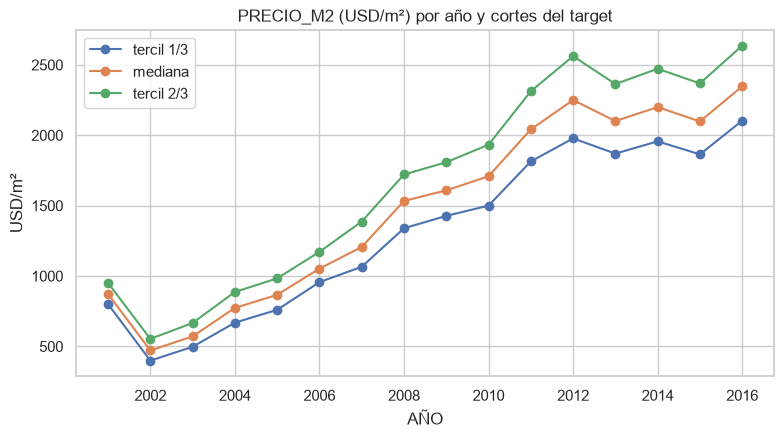

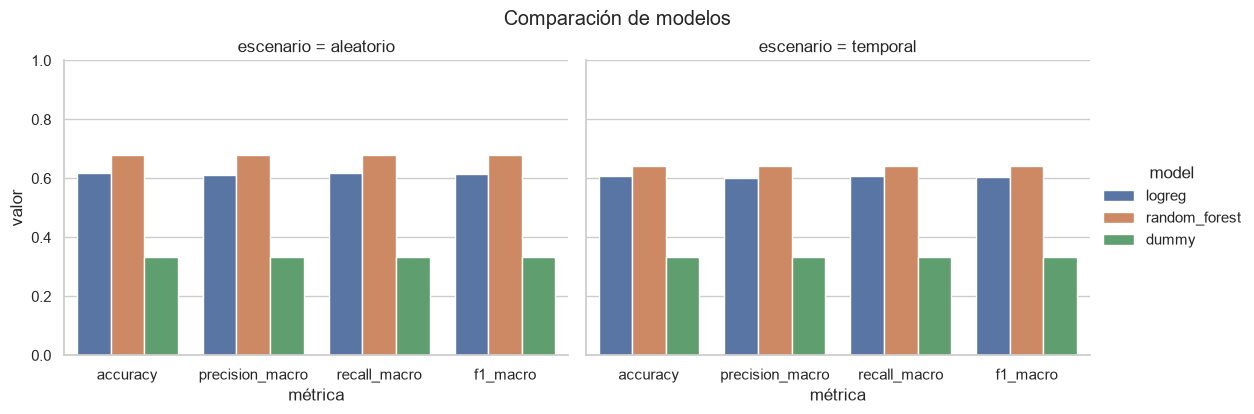

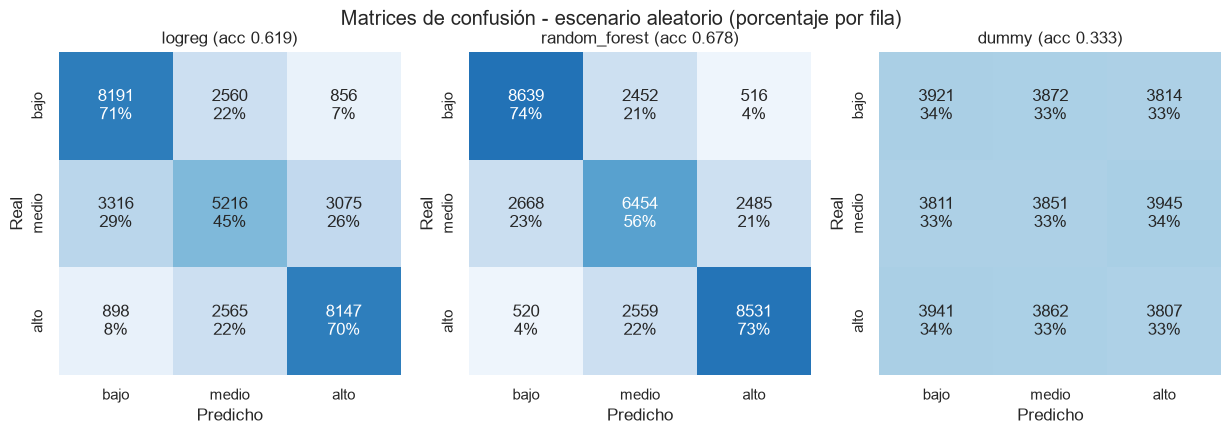

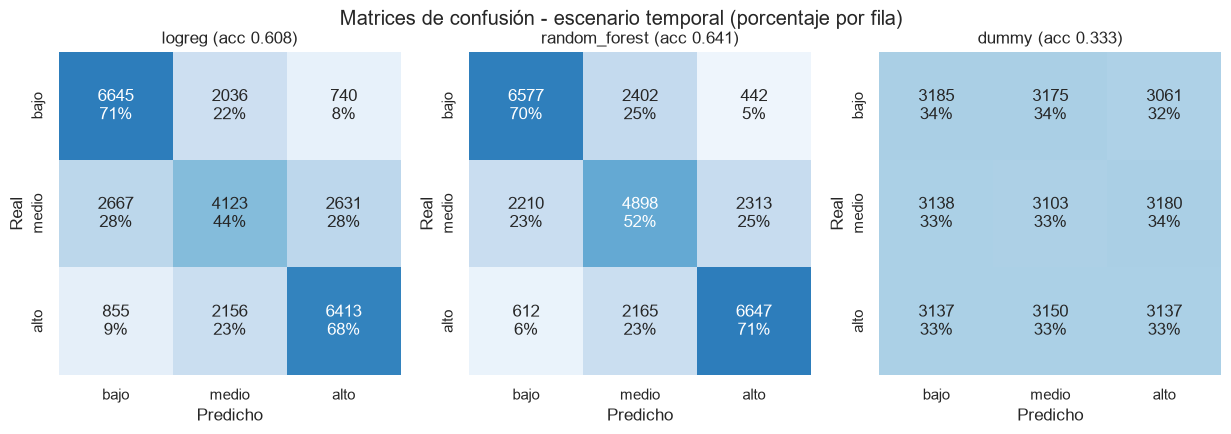

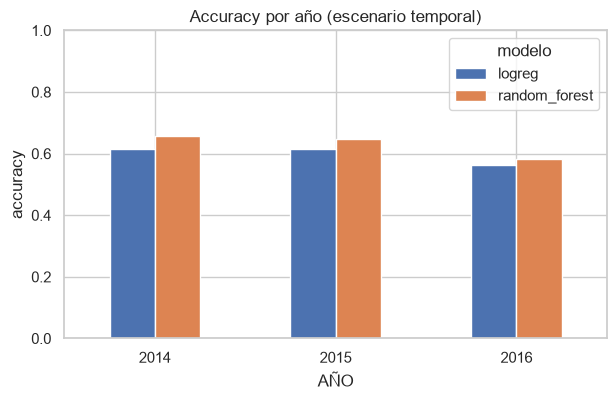

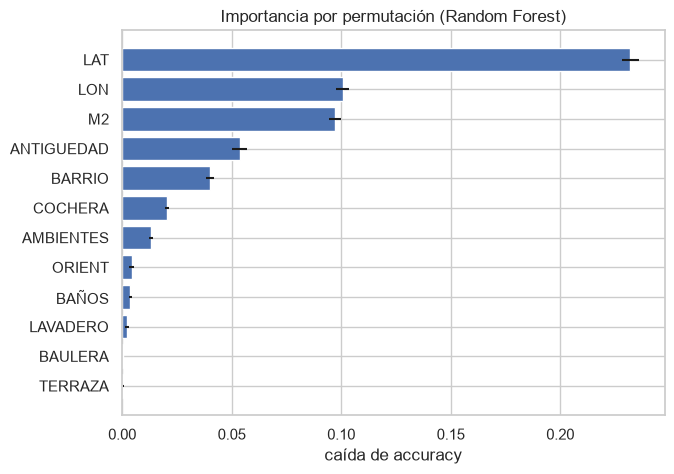

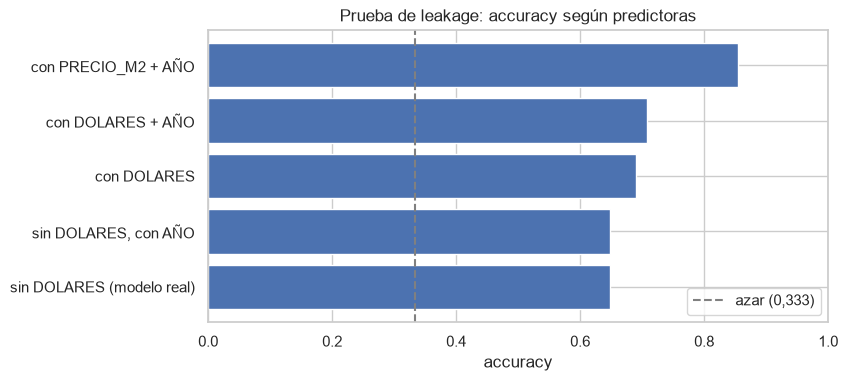

In [1]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2
import joblib, pandas as pd
import config
from src.db_sql import load_clean_data
from src.features import get_xy, split_data
from src.db_mongo import load_run
from src import visualization as viz
from src.logger_setup import flush_mongo_logs

df = load_clean_data()
viz.plot_price_by_year(df)

met = pd.concat([load_run("metricas", e) for e in ("aleatorio", "temporal")], ignore_index=True)
cols = ["escenario", "model", "accuracy", "precision_macro", "recall_macro", "f1_macro"]
display(met[cols].round(4))
viz.plot_model_comparison(met)
for e in ("aleatorio", "temporal"):
    viz.plot_confusion_matrices(met[met["escenario"] == e], e)

pred_t = load_run("predicciones", "temporal")
display(viz.plot_accuracy_by_year(pred_t[pred_t["modelo"] != "dummy"], df))

results = joblib.load(config.MODELS_DIR / "results.joblib")
X, y = get_xy(df)
_, X_test, _, y_test = split_data(X, y)
display(viz.plot_permutation_importance(results["random_forest"]["model"], X_test, y_test))

viz.plot_leakage(load_run("leakage", "leakage"))
flush_mongo_logs()